More concise version of "analysis2" notebook. Cite this notebook for reference.

In [1]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# --- Load Water Mass Codes ---
# Load the manual and correctly rename the columns
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
}) #[cite: 41, 44-49]

# --- Load and Combine Yearly Environmental Data ---
base_data_path = '../data/raw/environmental_data' #[cite: 159]
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames: #[cite: 164, 165]
        # Extract year from the folder name
        try:
            year = int(os.path.basename(dirpath).split('_')[0]) #[cite: 168]
        except (ValueError, IndexError):
            continue
        
        # Read shapefile, add year, and append to list
        shp_filepath = os.path.join(dirpath, 'output.shp') #[cite: 171]
        gdf_temp = gpd.read_file(shp_filepath) #[cite: 172]
        gdf_temp['year'] = year #[cite: 173]
        gdfs.append(gdf_temp) #[cite: 174]

# Concatenate all yearly data into one GeoDataFrame
all_points_gdf = pd.concat(gdfs, ignore_index=True) #[cite: 177]
print(f"Loaded and combined {len(all_points_gdf)} data points from {len(gdfs)} files.")

Loaded and combined 41346 data points from 84 files.


In [3]:
# --- Merge Datasets ---
# Ensure 'watercode' columns are the same integer type before merging
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int) #[cite: 270]
codes_df['watercode'] = codes_df['watercode'].astype(int) #[cite: 270]
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left') #[cite: 277]

# --- Create Season Column ---
def get_season(month): #[cite: 548]
    """Takes a month (1-12) and returns the corresponding season.""" #[cite: 549]
    if month in [12, 1, 2]: return 'Winter' #[cite: 550]
    elif month in [3, 4, 5]: return 'Spring' #[cite: 551]
    elif month in [6, 7, 8, 9]: return 'Summer' #[cite: 552]
    elif month in [10, 11]: return 'Autumn' #[cite: 553]
    else: return 'Unknown' #[cite: 556]

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season) #[cite: 557]

# --- Final Cleanup ---
# Ensure 'do_' column is a numeric type for calculations
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce') #[cite: 688]

print("Data merged and 'season' column created successfully.")
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head()) #[cite: 561]

Data merged and 'season' column created successfully.
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay


Number of measurement instances per month:
surveymont
1      9990
2       464
3         6
5     10168
6        30
7      9862
8       622
10    10080
11      114
12       10
Name: count, dtype: int64


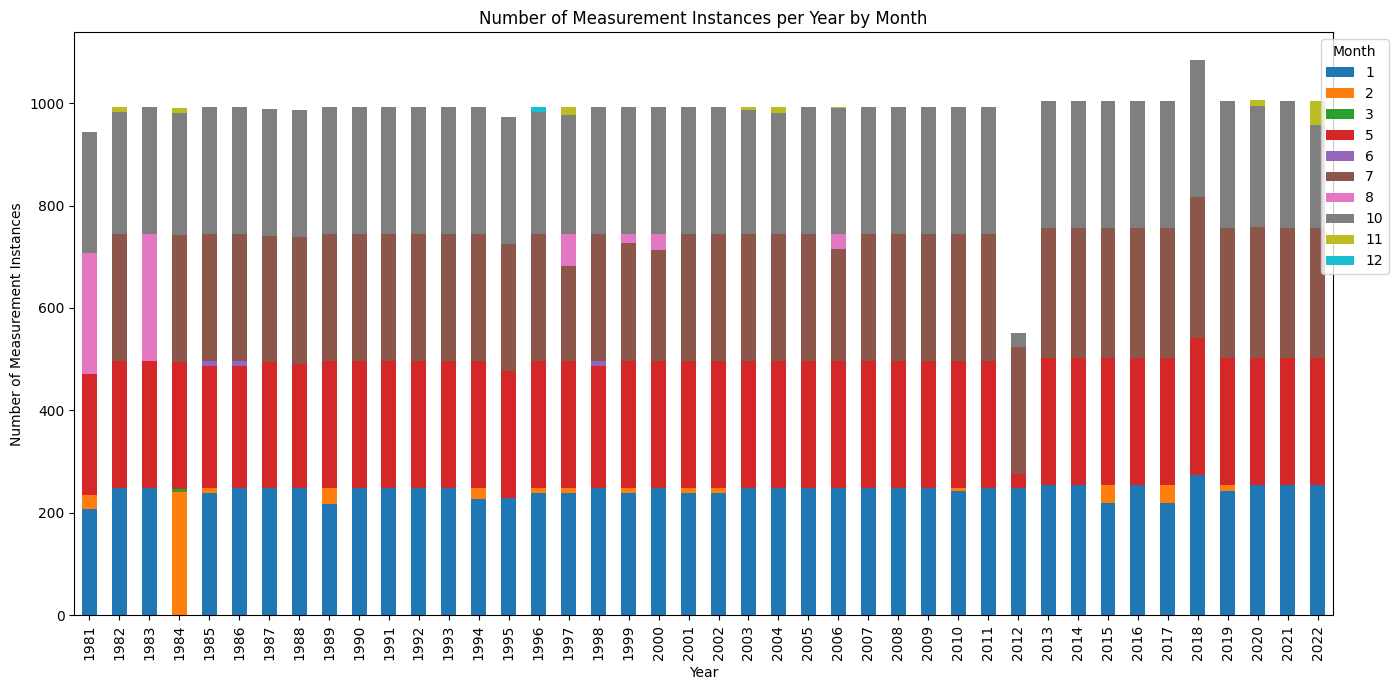

In [4]:
# Find out how many number of measurement instances recorded in every month

month_counts = merged_gdf['surveymont'].value_counts().sort_index()
print("Number of measurement instances per month:")
print(month_counts)

# Group by year and month, then count the number of measurements
counts = merged_gdf.groupby(['year', 'surveymont']).size().unstack(fill_value=0)
# rotate the years for better visualization 
counts = counts.reindex(sorted(counts.columns), axis=1)

# Plot as a grouped bar chart
counts.plot(kind='bar', stacked=True, figsize=(14, 7))

plt.xlabel('Year')
plt.ylabel('Number of Measurement Instances')
plt.title('Number of Measurement Instances per Year by Month')
plt.legend(title='Month', bbox_to_anchor=(1.05, 1), loc='upper right')
plt.tight_layout()
plt.show()

Prepared 5238 data points for analysis.


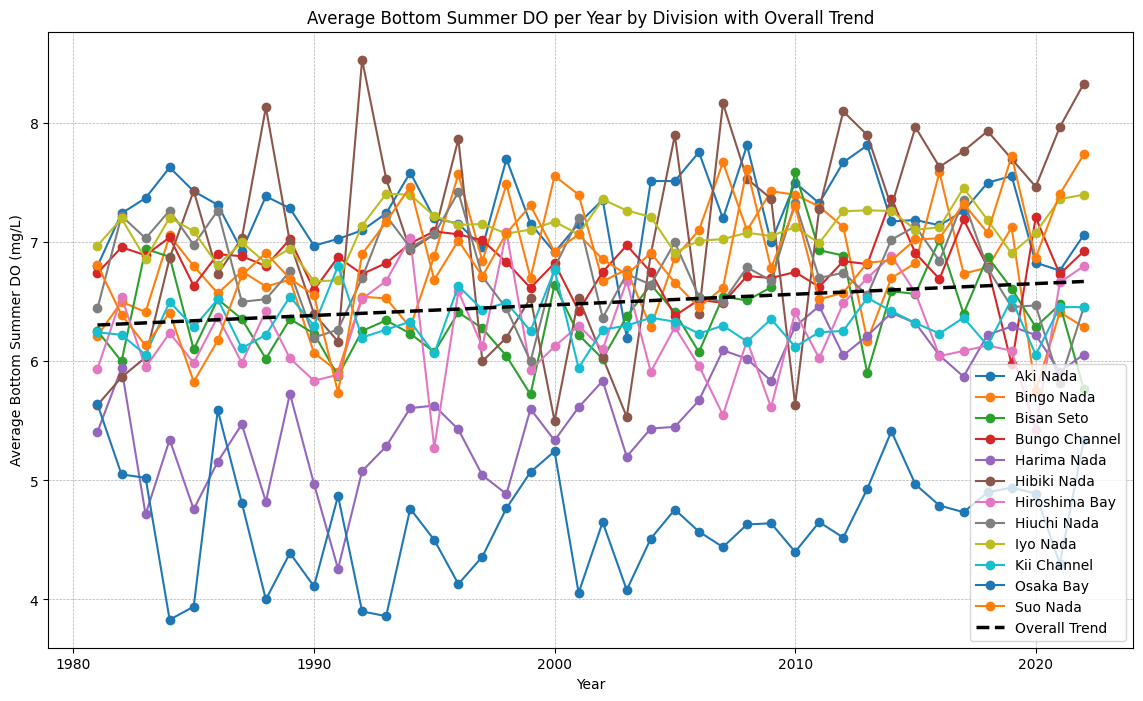

In [5]:
# Filter for summer bottom-layer data with valid DO measurements
avg_summer_bottom_do_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy() #[cite: 586, 615, 694]

print(f"Prepared {len(avg_summer_bottom_do_df)} data points for analysis.")

# --- Calculate Averages and Trend ---
# Group by division and year to get average DO
divisional_avg_do = avg_summer_bottom_do_df.groupby(['division', 'year'])['do_'].mean() #[cite: 589]

# Calculate the overall average DO across all divisions for each year
overall_avg_do = divisional_avg_do.groupby('year').mean() #[cite: 620]

# Perform linear regression to find the trend line
m, b = np.polyfit(overall_avg_do.index, overall_avg_do.values, 1) #[cite: 624]
trend_line = m * overall_avg_do.index + b #[cite: 625]

# --- Plot the Results ---
# Unstack data for easier plotting
plot_data = divisional_avg_do.unstack(level='division')

ax = plot_data.plot(
    marker='o', 
    figsize=(14, 8),
    title='Average Bottom Summer DO per Year by Division with Overall Trend',
    xlabel='Year',
    ylabel='Average Bottom Summer DO (mg/L)'
) #[cite: 647, 660-662]

# Plot the overall trend line
ax.plot(overall_avg_do.index, trend_line, color='black', linestyle='--', linewidth=2.5, label='Overall Trend') #[cite: 652-658]
ax.legend() #[cite: 651]
ax.grid(True, which='both', linestyle='--', linewidth=0.5) #[cite: 663]
plt.show()

In [6]:
# --- Setup for Map Generation ---
output_dir = '../reports/figures/yearly_avg_summer_bottom_do_maps_scatter' #[cite: 702]
os.makedirs(output_dir, exist_ok=True) #[cite: 703]

# Get consistent color limits for all maps
vmin = avg_summer_bottom_do_df['do_'].min() #[cite: 704, 705]
vmax = avg_summer_bottom_do_df['do_'].max() #[cite: 706]
years = sorted(avg_summer_bottom_do_df['year'].unique()) #[cite: 707]

# --- Loop to Create a Plot for Each Year ---
for year in years: #[cite: 710]
    year_data = avg_summer_bottom_do_df[avg_summer_bottom_do_df['year'] == year] #[cite: 712]
    if year_data.empty: #   [cite: 713]
        continue

    # Create the map
    fig = plt.figure(figsize=(12, 10)) #[cite: 717]
    ax = plt.axes(projection=ccrs.PlateCarree()) #[cite: 718]
    ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree()) #[cite: 719]
    ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1) #[cite: 721]
    ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False) #[cite: 723]

    # Create the scatter plot
    scatter = ax.scatter(
        year_data.geometry.x, year_data.geometry.y,
        c=year_data['do_'], cmap='jet_r',
        vmin=vmin, vmax=vmax, s=30, zorder=2,
        transform=ccrs.PlateCarree()
    ) #[cite: 724-737]

    # Add colorbar and title
    cbar = fig.colorbar(scatter, ax=ax, fraction=0.04, pad=0.04) #[cite: 739]
    cbar.set_label('Dissolved Oxygen (DO mg/L)')
    ax.set_title(f'Summer Bottom DO Distribution for {year}') #[cite: 740]

    # Save and close the figure
    output_path = os.path.join(output_dir, f'avg_summer_bottom_do_map_{year}.png') #[cite: 742]
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved map for {year}.")

print("\nAll yearly maps have been generated.")

Saved map for 1981.
Saved map for 1982.
Saved map for 1983.
Saved map for 1984.
Saved map for 1985.
Saved map for 1986.
Saved map for 1987.
Saved map for 1988.
Saved map for 1989.
Saved map for 1990.
Saved map for 1991.
Saved map for 1992.
Saved map for 1993.
Saved map for 1994.
Saved map for 1995.
Saved map for 1996.
Saved map for 1997.
Saved map for 1998.
Saved map for 1999.
Saved map for 2000.
Saved map for 2001.
Saved map for 2002.
Saved map for 2003.
Saved map for 2004.
Saved map for 2005.
Saved map for 2006.
Saved map for 2007.
Saved map for 2008.
Saved map for 2009.
Saved map for 2010.
Saved map for 2011.
Saved map for 2012.
Saved map for 2013.
Saved map for 2014.
Saved map for 2015.
Saved map for 2016.
Saved map for 2017.
Saved map for 2018.
Saved map for 2019.
Saved map for 2020.
Saved map for 2021.
Saved map for 2022.

All yearly maps have been generated.


Now let's try to plot the horizontal distribution of all the available recording instances of the sampling sites for each of the years.

In [7]:
# This script assumes 'merged_gdf' is already in your notebook's memory.

# Group the data by year and the location identifier, then count the size of each group.
# .size() counts the number of rows in each group, which equals the number of repetitions.
repetition_counts = merged_gdf.groupby(['year', 'locationna']).size()

# The result is a Series with a MultiIndex (year, locationna).
# Let's rename the column for clarity.
repetition_counts = repetition_counts.rename('repetition_count')

# Display the first 20 results to show a preview
print("Number of Sample Repetitions per Site per Year (Preview):")
print(repetition_counts.head(20))

Number of Sample Repetitions per Site per Year (Preview):
year  locationna
1981  兵庫県11         8
      兵庫県119        8
      兵庫県129        8
      兵庫県132        8
      兵庫県143        8
      兵庫県150        8
      兵庫県153        8
      兵庫県168        8
      兵庫県169        8
      兵庫県23         8
      兵庫県48         8
      和歌山県64        8
      和歌山県78        8
      和歌山県79        8
      和歌山県86        8
      和歌山県89        8
      大分県527        8
      大分県529        8
      大分県531        8
      大分県533        8
Name: repetition_count, dtype: int64


In [8]:
# set maximum row display to 0 (no limit)
pd.set_option('display.max_rows', None) # or use None for no limit

# Check the repetition counts for a specific year, for example, 2022
try:
    counts_2022 = repetition_counts.loc[2022]
    
    print("\nRepetition counts for the year 2022:")
    print(counts_2022)
    
    # You can also get a summary of the counts
    print("\nSummary of repetitions in 2022:")
    print(counts_2022.value_counts())

except KeyError:
    print("\nNo data found for the year 2022.")


Repetition counts for the year 2022:
locationna
兵庫県11     8
兵庫県119    8
兵庫県129    8
兵庫県132    8
兵庫県143    8
兵庫県150    8
兵庫県153    8
兵庫県168    8
兵庫県169    8
兵庫県23     8
兵庫県48     8
和歌山県64    8
和歌山県78    8
和歌山県79    8
和歌山県86    8
和歌山県89    8
大分県527    8
大分県528    4
大分県529    8
大分県531    8
大分県533    8
大分県575    8
大分県578    8
大分県594    8
大分県605    8
大分県677    8
大分県679    8
大分県680    8
大分県690    8
大分県696    8
大分県702    8
大阪府2      8
大阪府25     8
大阪府37     8
大阪府44     8
大阪府5      8
大阪府50     8
大阪府58     8
山口県412    8
山口県426    8
山口県433    8
山口県459    8
山口県473    8
山口県484    8
山口県486    8
山口県487    8
山口県498    8
山口県509    8
山口県512    8
山口県521    8
山口県522    8
山口県542    8
山口県550    8
山口県562    8
山口県565    8
山口県582    8
山口県588    8
山口県598    8
山口県613    8
山口県626    8
山口県707    8
岡山県182    8
岡山県204    8
岡山県224    8
岡山県237    8
岡山県241    8
岡山県248    8
岡山県276    8
岡山県277    8
広島県285    8
広島県310    8
広島県312    8
広島県313    4
広島県332    8
広島県344    8
広島県352    8
広島県363    8
広島県376    8
広島県382    8
広島県

This shows that in each year, almost all of the sampling locations had 8 repitions of sampling instances.

Now, for the fun part. Epic heat map visualization of all of the DO level using a contour map. First, let's try summer.

In [9]:
from scipy.interpolate import griddata

# --- 1. Prepare the Data (avg_summer_bottom_do_df) ---
print(f"Prepared {len(avg_summer_bottom_do_df)} data points for summer bottom layer analysis.")

# --- 2. Setup for the Loop ---
output_dir = '../reports/figures/yearly_summer_do_heatmaps'
os.makedirs(output_dir, exist_ok=True)
vmin = avg_summer_bottom_do_df['do_'].min()
vmax = avg_summer_bottom_do_df['do_'].max()
years = sorted(avg_summer_bottom_do_df['year'].unique())
extent = [130.6, 135.6, 32.75, 35.1]

# --- 3. Loop to Create a Heatmap for Each Year ---
for year in years:
    year_data = avg_summer_bottom_do_df[avg_summer_bottom_do_df['year'] == year]
    
    if len(year_data) < 4: # Need at least 4 points to interpolate
        print(f"Not enough data for {year}, skipping.")
        continue

# --- 4. Interpolation Steps ---
    # Get points (x,y) and values (z) from the GeoDataFrame
    points = np.array([year_data.geometry.x, year_data.geometry.y]).T
    values = year_data['do_'].values
    
    # Create a grid to interpolate onto (e.g., 200x200 resolution)
    grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]
    
    # Interpolate the data onto the grid
    grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

    # --- 5. Plotting ---
    fig = plt.figure(figsize=(12, 10))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    
    ax.add_feature(cfeature.LAND, edgecolor='black', zorder=2)
    ax.add_feature(cfeature.OCEAN, zorder=0)
    ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

    # Plot the interpolated data as a filled contour map
    contour = ax.contourf(
        grid_x, grid_y, grid_z,
        levels=np.linspace(vmin, vmax, 15), # 15 color levels
        cmap='jet_r',
        vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree(),
        zorder=1
    )
    
    cbar = fig.colorbar(contour, ax=ax, orientation='vertical', fraction=0.04, pad=0.05)
    cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')
    ax.set_title(f'Summer Bottom DO Distribution (Interpolated) for {year}')
    
    # Save the figure
    output_path = os.path.join(output_dir, f'do_heatmap_{year}.png')
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    
    # print(f"Saved heatmap for {year} to {output_path}")

print("\n✅ All yearly heatmaps have been generated.")

Prepared 5238 data points for summer bottom layer analysis.

✅ All yearly heatmaps have been generated.


This is for making heatmaps for all season.

Prepared 20631 total bottom layer data points for analysis.


KeyboardInterrupt: 

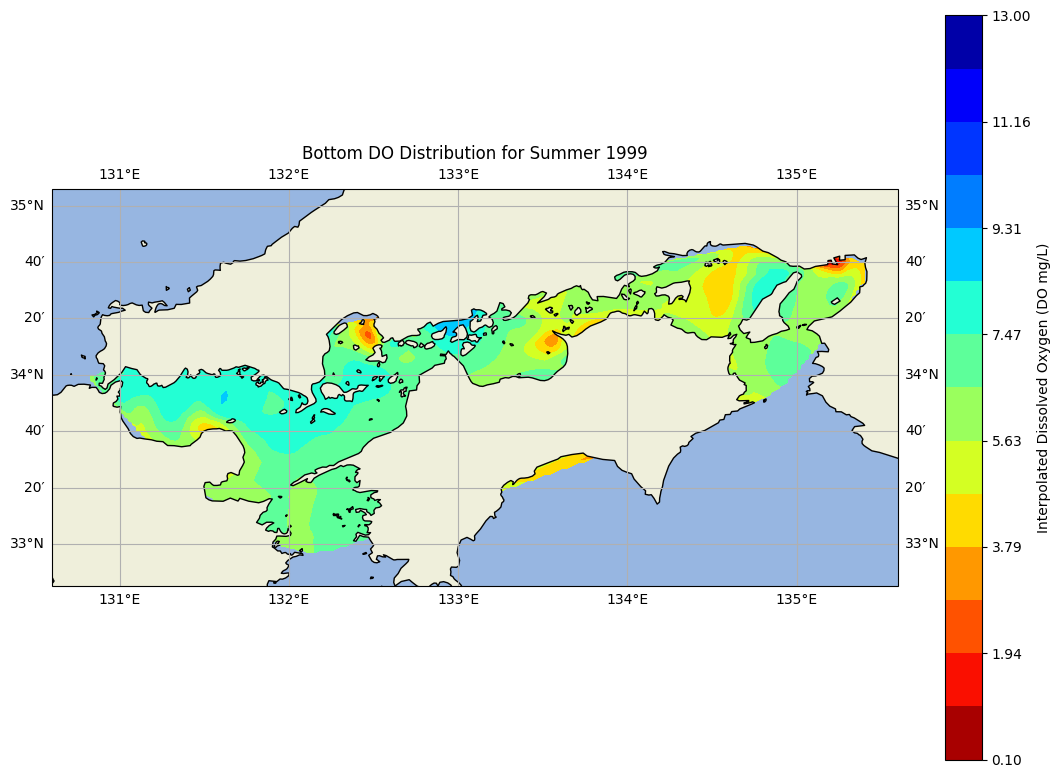

In [10]:
# This assumes 'merged_gdf' is already in your notebook's memory.

# --- 1. Prepare the Data ---
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce')
# We now filter for the bottom layer first from the entire dataset
bottom_layer_gdf = merged_gdf[merged_gdf['saisuipoin'] == 2].copy()
bottom_layer_gdf.dropna(subset=['do_', 'geometry'], inplace=True)

print(f"Prepared {len(bottom_layer_gdf)} total bottom layer data points for analysis.")

# --- 2. Setup for the Loops ---
output_dir = '../reports/figures/seasonal_do_heatmaps'
os.makedirs(output_dir, exist_ok=True)

# Calculate color scale from the entire dataset for consistency
vmin = bottom_layer_gdf['do_'].min()
vmax = bottom_layer_gdf['do_'].max()

years = sorted(bottom_layer_gdf['year'].unique())
seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
extent = [130.6, 135.6, 32.75, 35.1]

# --- 3. Loop Through Each Year and Each Season ---
for year in years:
    for season in seasons:
        # Filter data for the specific year AND season
        year_season_data = bottom_layer_gdf[
            (bottom_layer_gdf['year'] == year) &
            (bottom_layer_gdf['season'] == season)
        ]
        
        if len(year_season_data) < 4: # Need at least 4 points to interpolate
            print(f"Not enough data for {year} {season}, skipping.")
            continue

        # --- Interpolation ---
        points = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
        values = year_season_data['do_'].values
        grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]
        grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

        # --- Plotting ---
        fig = plt.figure(figsize=(12, 10))
        ax = plt.axes(projection=ccrs.PlateCarree())
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        
        ax.add_feature(cfeature.LAND, edgecolor='black', zorder=2)
        ax.add_feature(cfeature.OCEAN, zorder=0)
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

        contour = ax.contourf(
            grid_x, grid_y, grid_z,
            levels=np.linspace(vmin, vmax, 15),
            cmap='jet_r',
            vmin=vmin, vmax=vmax,
            transform=ccrs.PlateCarree(),
            zorder=1
        )
        
        cbar = fig.colorbar(contour, ax=ax, orientation='vertical', fraction=0.04, pad=0.05)
        cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')
        ax.set_title(f'Bottom DO Distribution for {season} {year}')
        
        # Save the figure with a unique name
        output_path = os.path.join(output_dir, f'do_heatmap_{year}_{season}.png')
        plt.savefig(output_path, dpi=150, bbox_inches='tight')
        plt.close(fig)
        
        #print(f"Saved map for {year} {season} to {output_path}")

print("\n✅ All seasonal heatmaps have been generated.")

Next, let's calculate the total hypoxic area from each season from each year. And then we'll save it into a new dataframe.

In [ ]:
# This assumes 'bottom_layer_gdf' is prepared from the previous step.

# --- 1. Setup ---
hypoxic_threshold = 2.0 # DO level in mg/L
results = [] # A list to store our calculated results
extent = [130.6, 135.6, 32.75, 35.1]
grid_res_x, grid_res_y = (200j, 200j) # Grid resolution from previous step

# Calculate the area of a single grid cell in square degrees
# This is an approximation; for precise area, a different map projection would be needed,
# but for comparing relative changes, this is sufficient.
lat_dist = 111 # Approx km per degree latitude
lon_dist = np.cos(np.radians(np.mean(extent[2:]))) * 111.32 # Approx km per degree longitude at this latitude
cell_area_km2 = ((extent[1] - extent[0]) / (grid_res_x.imag - 1)) * lon_dist * \
                ((extent[3] - extent[2]) / (grid_res_y.imag - 1)) * lat_dist

years = sorted(bottom_layer_gdf['year'].unique())
seasons = ['Winter', 'Spring', 'Summer', 'Autumn']

# --- 2. Loop Through Data to Calculate Hypoxic Area ---
for year in years:
    for season in seasons:
        year_season_data = bottom_layer_gdf[
            (bottom_layer_gdf['year'] == year) &
            (bottom_layer_gdf['season'] == season)
        ]
        
        if len(year_season_data) < 4:
            continue

        points = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
        values = year_season_data['do_'].values
        grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
        grid_z = griddata(points, values, (grid_x, grid_y), method='cubic') # Use 'nearest' to avoid NaNs

        # --- CALCULATION ---
        # Count the number of grid cells where DO is below the threshold
        hypoxic_cells = np.sum(grid_z < hypoxic_threshold)
        
        # Calculate the total area of hypoxia
        hypoxic_area = hypoxic_cells * cell_area_km2
        
        # Store the result
        results.append({
            'year': year,
            'season': season,
            'hypoxic_area_km2': hypoxic_area
        })

# --- 3. Create a new DataFrame from the results ---
hypoxia_df = pd.DataFrame(results)

print("Analysis Complete. Preview of the new hypoxic area dataset:")
print(hypoxia_df.head())

Analysis Complete. Preview of the new hypoxic area dataset:
   year  season  hypoxic_area_km2
0  1981  Winter          0.000000
1  1981  Spring          0.000000
2  1981  Summer        109.518507
3  1981  Autumn          0.000000
4  1982  Winter          0.000000


In [ ]:
# Check the minimum DO value for each season in your dataset
min_do_by_season = bottom_layer_gdf.groupby('season')['do_'].min()

print("Minimum DO value observed for each season:")
print(min_do_by_season)

Minimum DO value observed for each season:
season
Autumn    0.7
Spring    0.5
Summer    0.1
Winter    1.0
Name: do_, dtype: float64


To make it easier to the eye, let's make a gif animation of the bottom do level of each season for every year. Each frame of the gif will contain the horizontal distribiution of bottom DO level for all four season for that specific year. The gif will show the plot starting from 1981 to 2022.

In [ ]:
# 2x2 format of seasonal maps per year
# This is where it does the thing

# --- 1. Prepare the Data ---
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce')
bottom_layer_gdf = merged_gdf[merged_gdf['saisuipoin'] == 2].copy()
bottom_layer_gdf.dropna(subset=['do_', 'geometry'], inplace=True)
print(f"Prepared {len(bottom_layer_gdf)} total bottom layer data points for analysis.")

# --- 2. Setup for the Loops ---
output_dir = '../reports/figures/seasonal_gif_frames'
os.makedirs(output_dir, exist_ok=True)

vmin = bottom_layer_gdf['do_'].min()
vmax = bottom_layer_gdf['do_'].max()
years = sorted(bottom_layer_gdf['year'].unique())
seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
extent = [130.6, 135.6, 32.75, 35.1]
grid_res_x, grid_res_y = (100j, 100j) # Reduced resolution slightly for faster processing

# --- 3. Main Loop to Create a 2x2 Plot for Each Year ---
for year in years:
    # Create the 2x2 subplot figure
    fig, axes = plt.subplots(
        2, 2, figsize=(15, 12),
        subplot_kw={'projection': ccrs.PlateCarree()}
    )
    fig.suptitle(f'Seasonal Bottom DO Distribution for {year}', fontsize=16)

    # Flatten the 2x2 axes array for easy iteration
    axes = axes.flatten()
    
    # Store the last contour plot for the colorbar
    last_contour = None

    # Inner loop to create a map for each season
    for i, season in enumerate(seasons):
        ax = axes[i]
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.OCEAN, zorder=0)
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        ax.set_title(season)

        # Filter data for the specific year AND season
        year_season_data = bottom_layer_gdf[
            (bottom_layer_gdf['year'] == year) &
            (bottom_layer_gdf['season'] == season)
        ]
        
        if len(year_season_data) > 3:
            # --- Interpolation ---
            points = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
            values = year_season_data['do_'].values
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
            grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

            # --- Plotting the heatmap ---
            contour = ax.contourf(
                grid_x, grid_y, grid_z,
                levels=np.linspace(vmin, vmax, 15),
                cmap='jet_r',
                vmin=vmin, vmax=vmax,
                transform=ccrs.PlateCarree(),
                zorder=1
            )
            last_contour = contour
        else:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, ha='center', va='center', fontsize=15)
    
    # --- FIX 1: Draw Land and Coastlines on TOP of the heatmap ---
        ax.add_feature(cfeature.LAND, edgecolor='black', zorder=2)
        ax.add_feature(cfeature.COASTLINE, zorder=2)
        
    # --- 4. Add a single colorbar for the whole figure ---
    if last_contour:
        cbar = fig.colorbar(last_contour, ax=axes, orientation='vertical', fraction=0.02, pad=0.05)
        cbar.set_label('Interpolated Dissolved Oxygen (DO mg/L)')

    fig.subplots_adjust(hspace=0.3, wspace=0.3)

    # Save the composite figure for the year
    output_path = os.path.join(output_dir, f'frame_{year}.png')
    plt.savefig(output_path, dpi=100, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved frame for {year} to {output_path}")

Prepared 20631 total bottom layer data points for analysis.
Saved frame for 1981 to ../reports/figures/seasonal_gif_frames\frame_1981.png
Saved frame for 1982 to ../reports/figures/seasonal_gif_frames\frame_1982.png
Saved frame for 1983 to ../reports/figures/seasonal_gif_frames\frame_1983.png
Saved frame for 1984 to ../reports/figures/seasonal_gif_frames\frame_1984.png
Saved frame for 1985 to ../reports/figures/seasonal_gif_frames\frame_1985.png
Saved frame for 1986 to ../reports/figures/seasonal_gif_frames\frame_1986.png
Saved frame for 1987 to ../reports/figures/seasonal_gif_frames\frame_1987.png
Saved frame for 1988 to ../reports/figures/seasonal_gif_frames\frame_1988.png
Saved frame for 1989 to ../reports/figures/seasonal_gif_frames\frame_1989.png
Saved frame for 1990 to ../reports/figures/seasonal_gif_frames\frame_1990.png
Saved frame for 1991 to ../reports/figures/seasonal_gif_frames\frame_1991.png
Saved frame for 1992 to ../reports/figures/seasonal_gif_frames\frame_1992.png
Save

In [ ]:

# --- 5. Create the Final GIF Animation ---
print("\nStitching frames into a GIF...")
images = []
file_list = sorted(glob.glob(os.path.join(output_dir, '*.png')))

for filename in file_list:
    images.append(imageio.imread(filename))

gif_path = '../reports/figures/animations/seasonal_do_animation.gif'
imageio.mimsave(gif_path, images, fps=1) # 1 second per year

print(f"✅ Animation saved successfully to {gif_path}")


Stitching frames into a GIF...


ValueError: all input arrays must have the same shape

In [ ]:
def create_yearly_heatmap():
    year_data = data[data['year'] == year]
    if len(year_data) < 4:
        print(f"Not enough data for {year}, skipping.")
        return # Exit the function

# --- Interpolation ---
    points = np.array([year_data.geometry.x, year_data.geometry.y]).T
    values = year_data['do_'].values
    grid_x, grid_y = np.mgrid[130.6:135.6:200j, 32.75:35.1:200j]
    grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

# --- Plotting ---
    fig = plt.figure(figsize=(12, 10))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, edgecolor='black', zorder=2)

    contour = ax.contourf(
    grid_x, grid_y, grid_z,
    levels=np.linspace(vmin, vmax, 15),
    cmap='jet_r', transform=ccrs.PlateCarree()
    zorder=1
)
    cbar = fig.colorbar(contour, ax=ax, fraction=0.1, pad=0.5)
    cbar.set_label('Interpolated DO (mg/L)')
    ax.set_title(f'Summer Bottom DO Distribution for {year}')

# Save and close the figure
    output_path = os.path.join(output_dir, f'do_heatmap_{year}.png')
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved map for {year}."),

return create_yearly_heatmap()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3797783734.py, line 22)